# 추가 실험: 학습 원본 확대와 고정 평가 자료 비교

기존 제출용 노트북과 PPT는 그대로 보관하고, 학습 원본만 늘려 두 CNN을 새로 학습하는 노트북이다.
과일별 원본 3,000장을 상한으로 하며, 부족한 종류는 확보 가능한 학습 원본을 사용한다. 증강본을 원본으로 세지 않는다.

기존 학습의 실험 폴더와 원본 사진이 필요하다. 기본 실험은 저장소 루트의 `train.ipynb`에서 실행한다.

VS Code에서 이 파일이 있는 프로젝트 폴더를 열고 원래 노트북과 같은 Python 커널·패키지를 사용한다. 최초 사진 다운로드에는 인터넷이 필요하다.

## 실행 경로

1 → 2 → 3 → 4를 실행하면 다운로드, 전처리, 두 CNN 학습, 기존 대비 평가를 수행한다. 전체 학습은 CPU에서 수십 분 걸릴 수 있다. 결과만 볼 때는 5번, 저장된 확대 모델로 사진을 고를 때는 6번을 실행한다. Run All은 마지막 사진 선택 단계에서 사용자 입력을 기다린다.
기존 검증 900장과 테스트 500장은 유지하며, 검증용 폴더 전체를 학습 후보에서 제외한다. 테스트 선화가 기존 입력과 완전히 같은지 확인한 뒤 학습을 시작한다.

모델 구조, 초기화 seed 42, 배치 32, Adam 0.0003, 25 epochs, 원본당 추가 증강 2개, 검증 손실 최소 모델 선택 규칙을 유지한다.
메모리 사용을 줄이기 위해 학습 입력을 uint8 파일로 저장하고 배치별 float32로 읽는다. 클래스 가중치는 동일한 공식으로 계산한 뒤 표본별 가중치로 전달한다.

**해석 범위:** 원본 수와 함께 품종·촬영 폴더의 다양성, 클래스 비율, 에폭당 배치 수와 총 업데이트 수도 달라진다. 따라서 결과를 사진 장수만의 순수한 효과로 단정하지 않는다.
원본 중복을 제거하지만 같은 실제 과일의 유사 프레임을 완전히 구분한다는 보장은 없다. 새 실제 사진의 일반화 성능은 별도 평가가 필요하다.

## 이번에 완료한 저장 실험의 결과

실험 폴더: `run_20261105_152142_420933`

기존 검증 900장과 테스트 500장을 고정했다. 기존 모델과 제출본은 변경하지 않았다. 과일별 3,000장을 상한으로 사용 가능 원본을 늘렸으며, 원본당 추가 증강 2개를 유지했다.

| 과일 | 기존 원본 | 확대 원본 | 확대 학습 입력(증강 포함) |
|---|---:|---:|---:|
| 사과 | 300 | 3000 | 9000 |
| 바나나 | 300 | 1690 | 5070 |
| 레몬 | 225 | 492 | 1476 |
| 딸기 | 300 | 759 | 2277 |
| 파인애플 | 225 | 490 | 1470 |

| CNN | 기존 정확도 | 확대 정확도 | 변화 | 기존 Macro F1 | 확대 Macro F1 |
|---|---:|---:|---:|---:|---:|
| outline | 84.4% | 85.6% | +1.2%p | 0.8423 | 0.8557 |
| lineart | 95.8% | 92.6% | -3.2%p | 0.9574 | 0.9251 |

원본 수와 함께 품종·촬영 폴더의 다양성, 클래스 구성, 에폭당 배치 수와 총 업데이트 수도 바뀌었다. 장수만의 순수한 효과로 단정하지 않는다. 클래스 가중치는 기존과 같은 공식으로 새 구성에서 다시 계산했다. 디스크 배치로 입력을 공급했으며, CNN 구조와 기본 학습 조건은 유지했다.

캐시된 바나나 이미지 1장의 읽기 실패로 해당 파일은 이번 실험에서 제외했다. 제외 사유와 경로는 preprocessing_audit.csv에 남겼다. 다음 실행에서 캐시 파일을 검증·재다운로드하면 수량이 달라질 수 있다.

시드 42 한 번의 결과다. 테스트 결과를 보고 반복 선택한 방법은 독립 평가 자료에서 재검증해야 한다. 실제 사진의 탐지·분리·일반화 개선을 입증한 실험은 아니다.

외곽선 학습 완료 후 설정 기록 저장에서 인코딩 오류가 발생했으나 저장된 최저 검증 손실 가중치와 25회 이력을 복구했다. 외곽선을 재학습하지 않고 선화 학습을 이어 완료했다. 외곽선 seconds는 로그에 표시된 반올림 에폭 시간을 합한 근삿값이며 timing_note에 기록했다.

상세 지표: report/baseline_vs_expanded_primary.csv, report/per_class_metrics.csv, report/auc_metrics.csv.

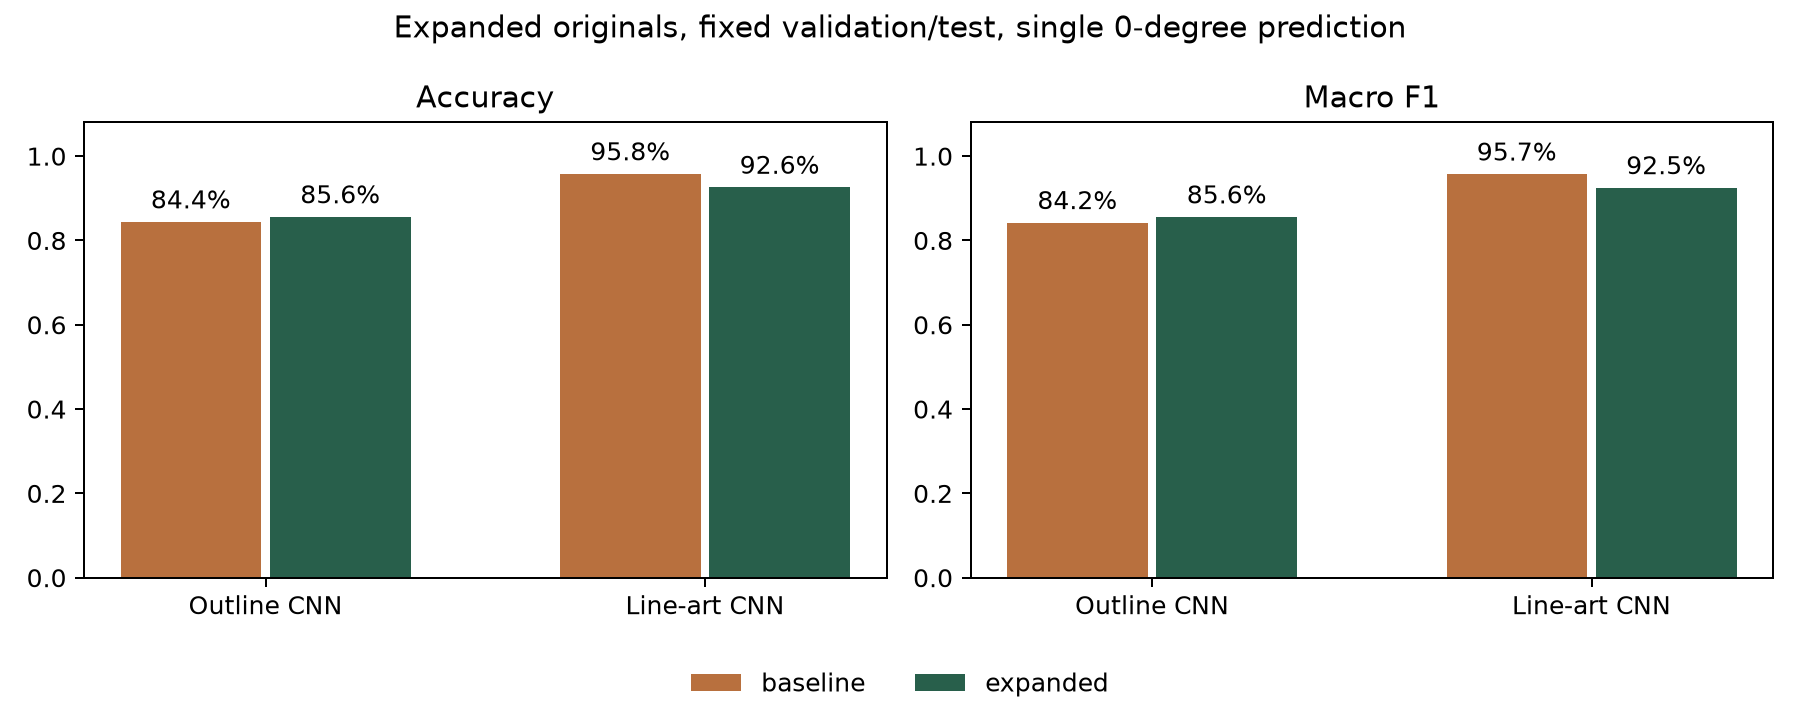


## 1. 추가 학습 사진 목록과 다운로드

기존 학습 원본을 포함하고, 고정 검증 폴더를 제외한 사진을 추가한다. 파일이 있으면 재사용한다. 출력 표의 계획 수량은 중복·전처리 검사 전 값이다.

In [ ]:
"""Run the expanded experiment separately, keeping the baseline holdouts fixed."""
from pathlib import Path
import os, json, ast, hashlib, io, time, gc
from urllib.request import Request, urlopen
from urllib.parse import quote
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
from PIL import Image

os.environ.setdefault('MPLBACKEND','Agg')
WORKSPACE=Path.cwd()
os.chdir(WORKSPACE)
BASELINE=WORKSPACE/'fruit_outline_project/results/controlled_outline_vs_lineart_v1/run_20261104_121829_f10503'
if not (BASELINE/'conditions.json').exists():
    registry = BASELINE.parent/'latest_experiment.json'
    if not registry.exists():
        raise FileNotFoundError('먼저 train.ipynb의 기본 비교 실험을 실행하세요.')
    registered = Path(json.loads(registry.read_text(encoding='utf-8'))['run_dir'])
    relocated = registry.parent/registered.name
    BASELINE = relocated if relocated.exists() else registered
ROOT=WORKSPACE/'fruit_outline_project'
DATA_DIR=ROOT/'photos'
META_DIR=ROOT/'metadata'
TARGET_PER_CLASS=3000
classes=['apple','banana','lemon','strawberry','pineapple']
COMMIT=json.loads((BASELINE/'conditions.json').read_text())['source_commit']
REPO='fruits-360/fruits-360-100x100'
API=f'https://api.github.com/repos/{REPO}'

def tree(sha):
    endpoint='/git/trees/'+sha
    p=META_DIR/(hashlib.sha256(endpoint.encode()).hexdigest()+'.json')
    if p.exists():data=json.loads(p.read_text())
    else:
        headers={'User-Agent':'FruitOutlineNotebook','Accept':'application/vnd.github+json'}
        if os.environ.get('GITHUB_TOKEN'):headers['Authorization']='Bearer '+os.environ['GITHUB_TOKEN']
        with urlopen(Request(API+endpoint,headers=headers),timeout=60) as response:data=json.load(response)
        p.write_text(json.dumps(data),encoding='utf-8')
    if data.get('truncated'):raise RuntimeError('Truncated file listing')
    return data['tree']

baseline=pd.read_csv(BASELINE/'source_split.csv')
heldout=baseline[baseline.split.isin(['val','test'])].copy()
excluded_folders=set(heldout.loc[heldout.split=='val','source_folder'])
top={e['path']:e for e in tree(COMMIT)}
folders={e['path']:e for e in tree(top['Training']['sha']) if e['type']=='tree'}
prefixes=dict(zip(classes,['Apple ','Banana ','Lemon ','Strawberry ','Pineapple ']))
records=[];availability=[];source_folders={}
for label in classes:
    old=baseline[(baseline.split=='train')&(baseline['class']==label)].to_dict('records')
    oldpaths={r['source_path'] for r in old}
    eligible=sorted(n for n in folders if n.startswith(prefixes[label]) and n not in excluded_folders and 'Wedge' not in n)
    groups=[]
    for name in eligible:
        files=sorted('Training/'+name+'/'+e['path'] for e in tree(folders[name]['sha'])
                     if e['type']=='blob' and Path(e['path']).suffix.lower() in ['.jpg','.png','.jpeg'])
        availability.append({'class':label,'source_folder':name,'available':len(files),'excluded_validation_folder':False})
        groups.append([f for f in files if f not in oldpaths])
    rng=np.random.default_rng(42+classes.index(label))
    groups=[list(rng.permutation(g)) for g in groups]
    chosen=[]
    for i in range(max(map(len,groups),default=0)):
        for group in groups:
            if i<len(group):chosen.append(group[i])
    selected=old+[{'official_split':'Training','class':label,'label':classes.index(label),
                  'source_folder':f.split('/')[1],'source_path':f,'local_path':str(DATA_DIR/f),'split':'train'}
                 for f in chosen[:max(0,TARGET_PER_CLASS-len(old))]]
    for r in selected:r['local_path']=str(DATA_DIR/r['source_path'])
    records.extend(selected)
    source_folders[label]=sorted({r['source_folder'] for r in selected})
    print('AVAILABLE',label,'all eligible',len(old)+len(chosen),'selected',len(selected),flush=True)
records.extend(heldout.to_dict('records'))
for r in records:r['local_path']=str(DATA_DIR/r['source_path'])
prepared=pd.DataFrame(records)
stage=ROOT/'results/expanded_training_fixed_holdout_v1'
stage.mkdir(exist_ok=True,parents=True)
prepared.to_csv(stage/'planned_source_split.csv',index=False)
pd.DataFrame(availability).to_csv(stage/'source_availability.csv',index=False)

def download(row):
    p=Path(row['local_path'])
    if p.exists():
        try:
            with Image.open(p) as im:im.verify()
            return
        except OSError:pass
    url=f'https://raw.githubusercontent.com/{REPO}/{COMMIT}/'+quote(row['source_path'],safe='/')
    for attempt in range(4):
        try:
            with urlopen(Request(url,headers={'User-Agent':'FruitOutlineNotebook'}),timeout=45) as response:b=response.read()
            with Image.open(io.BytesIO(b)) as im:im.verify()
            p.parent.mkdir(parents=True,exist_ok=True)
            temporary=p.with_suffix(p.suffix+'.part');temporary.write_bytes(b);temporary.replace(p);return
        except Exception:
            if attempt==3:raise
            time.sleep(attempt+1)

print('DOWNLOAD',len(records),flush=True)
with ThreadPoolExecutor(max_workers=12) as pool:
    futures={pool.submit(download,r):r for r in records}
    for i,f in enumerate(as_completed(futures),1):
        f.result()
        if i%200==0 or i==len(futures):print('downloaded/cache',i,'/',len(futures),flush=True)

## 2. 공통 전처리와 평가 자료 고정 확인

원본에만 증강을 적용하고 외곽선·선화를 함께 생성한다. 기존 검증·테스트의 구성과 테스트 텐서가 동일하지 않으면 학습하지 않고 중단한다. 이 셀을 다시 실행하면 새 실험 폴더가 생긴다.

In [ ]:
# Reuse the notebook's preprocessing, CNN, learning and reporting code.
# 0-B 설정: 경로·대상·비교 조건을 정합니다. PPT 재현 시 기본 학습 조건을 유지하세요.
import os, io, json, time, hashlib, re
from pathlib import Path
from datetime import datetime
import uuid
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.request import Request, urlopen
from urllib.parse import quote
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

ROOT = Path.cwd() / 'fruit_outline_project'
DATA_DIR = ROOT / 'photos'
RESULT_DIR = ROOT / 'results' / 'lineart_v1_apple_banana_lemon_strawberry_pineapple'
CONTROLLED_ROOT = ROOT / 'results' / 'controlled_outline_vs_lineart_v1'
CONTROLLED_ROOT.mkdir(parents=True,exist_ok=True)
CONTROLLED_REGISTRY = CONTROLLED_ROOT / 'latest_experiment.json'
EXPERIMENT_SEEDS = [42]  # 보고서용 반복 실험: [42, 123, 2026]
for folder in [DATA_DIR, RESULT_DIR]: folder.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ['apple', 'banana', 'lemon', 'strawberry', 'pineapple']
CLASS_KO = ['사과', '바나나', '레몬', '딸기', '파인애플']
SEED = 42
IMAGE_SIZE, EPOCHS, BATCH_SIZE = 96, 25, 32
REPRESENTATION = 'fruit_lineart_v1'
MODEL_METADATA = None
MODEL_TO_LOAD = 'latest'  # 'original'로 바꾸면 최초 모델 사용
MODEL_REGISTRY = RESULT_DIR / 'latest_finetuned.json'
FEEDBACK_DIR = ROOT / 'reviewed_lineart'
FEEDBACK_INDEX = FEEDBACK_DIR / 'labels.json'
FINETUNE_DIR = RESULT_DIR / 'finetuned_versions'
ACTIVE_MODEL_PATH = RESULT_DIR / 'fruit_lineart_cnn.keras'
LAST_SCENE_DIR = None
MASK_CONFIG = dict(white_v=185, white_s=75, min_area_fraction=0.003)
LINEART_CONFIG = dict(margin=10, line_width=1, canny_low=35, canny_high=100,
                     adaptive_block=11, adaptive_c=5, bilateral_d=5, bilateral_sigma=35,
                     min_component_pixels=2)
AUGMENTED_VIEWS = 2  # 학습 원본마다 추가할 변형 수. 검증/테스트에는 추가하지 않음
OCCLUSION_PROBABILITY = 0.35
MAX_OCCLUSION_FRACTION = 0.20
# 자동 분리 모델과 GPU를 함께 사용할 때 TensorFlow가 메모리를 모두 선점하지 않도록 설정
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| OpenCV:', cv2.__version__)
print('저장 폴더:', ROOT)

CONTROLLED_ROOT=stage
CONTROLLED_REGISTRY=stage/'latest_experiment.json'
import matplotlib.pyplot as plt
plt.show=lambda:plt.close('all')
display=lambda x:print(x.to_string() if hasattr(x,'to_string') else x,flush=True)
# 2 함수 정의: 사진 읽기 → 마스크 정리 → 선화 생성 → 증강 → 예측 보조 함수.
def read_rgb(source):
    if isinstance(source,np.ndarray):
        if source.ndim!=3 or source.shape[2]!=3: raise ValueError('RGB 3채널 배열이 필요합니다.')
        return source.astype(np.uint8)
    with Image.open(source) as image:
        image=ImageOps.exif_transpose(image).convert('RGBA')
        white=Image.new('RGBA',image.size,(255,255,255,255))
        return np.asarray(Image.alpha_composite(white,image).convert('RGB'))

def clean_object_mask(mask):
    binary=(np.asarray(mask)>0).astype(np.uint8)*255
    if binary.ndim!=2: raise ValueError('물체 마스크는 2차원이어야 합니다.')
    contours,_=cv2.findContours(binary,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if not contours: raise ValueError('물체 영역이 없습니다.')
    contour=max(contours,key=cv2.contourArea)
    if cv2.contourArea(contour)<2: raise ValueError('물체 영역이 너무 작습니다.')
    clean=np.zeros_like(binary)
    cv2.drawContours(clean,[contour],-1,255,cv2.FILLED)
    return clean

def fruit_to_lineart(rgb,mask,image_size=96,margin=10,line_width=1,
                     canny_low=35,canny_high=100,adaptive_block=11,adaptive_c=5,
                     bilateral_d=5,bilateral_sigma=35,min_component_pixels=2):
    """학습과 실제 사진에 공통 적용: 외곽선 + 내부 명암 경계/무늬를 이진 선화로 변환."""
    rgb=read_rgb(rgb)
    clean=clean_object_mask(mask)
    if clean.shape!=rgb.shape[:2]: raise ValueError('사진과 마스크의 크기가 다릅니다.')
    if not 0<=margin<image_size/2: raise ValueError('선화 여백 설정이 잘못되었습니다.')
    if not 0<=canny_low<canny_high<=255: raise ValueError('Canny 기준값을 확인하세요.')
    if adaptive_block<3 or adaptive_block%2==0: raise ValueError('adaptive_block은 3 이상 홀수여야 합니다.')
    # 배경의 선이 CNN으로 전달되지 않도록 물체 외부를 먼저 흰색으로 치환
    isolated=rgb.copy(); isolated[clean==0]=255
    ys,xs=np.where(clean>0)
    x,y,w,h=int(xs.min()),int(ys.min()),int(xs.max()-xs.min()+1),int(ys.max()-ys.min()+1)
    ratio=(image_size-2*margin)/max(w,h)
    nw,nh=max(1,round(w*ratio)),max(1,round(h*ratio))
    left,top=(image_size-nw)//2,(image_size-nh)//2
    normalized_rgb=np.full((image_size,image_size,3),255,np.uint8)
    normalized_mask=np.zeros((image_size,image_size),np.uint8)
    interp=cv2.INTER_AREA if ratio<1 else cv2.INTER_CUBIC
    normalized_rgb[top:top+nh,left:left+nw]=cv2.resize(isolated[y:y+h,x:x+w],(nw,nh),interpolation=interp)
    normalized_mask[top:top+nh,left:left+nw]=cv2.resize(clean[y:y+h,x:x+w],(nw,nh),interpolation=cv2.INTER_NEAREST)
    normalized_rgb[normalized_mask==0]=255
    gray=cv2.cvtColor(normalized_rgb,cv2.COLOR_RGB2GRAY)
    smooth=cv2.bilateralFilter(gray,int(bilateral_d),float(bilateral_sigma),float(bilateral_sigma))
    canny=cv2.Canny(smooth,int(canny_low),int(canny_high),L2gradient=True)
    dark_details=255-cv2.adaptiveThreshold(smooth,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                         cv2.THRESH_BINARY,int(adaptive_block),float(adaptive_c))
    # 흰 배경과 만나는 경계 띠를 내부 특징으로 오인하지 않도록 제외
    radius=max(2,int(adaptive_block)//2)
    interior=cv2.erode(normalized_mask,np.ones((2*radius+1,2*radius+1),np.uint8),iterations=1)
    detail_edges=cv2.Canny(dark_details,50,150)
    internal=cv2.bitwise_and(cv2.bitwise_or(canny,detail_edges),interior)
    # 작은 점 잡음은 제거하되, 씨/껍질 무늬 등 연결된 작은 특징은 유지
    if min_component_pixels>1:
        count,labels,stats,_=cv2.connectedComponentsWithStats(internal,connectivity=8)
        keep=np.zeros(count,np.uint8)
        if count>1: keep[1:]=(stats[1:,cv2.CC_STAT_AREA]>=min_component_pixels).astype(np.uint8)*255
        internal=keep[labels]
    outline=np.zeros_like(normalized_mask)
    contours,_=cv2.findContours(normalized_mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(outline,contours,-1,255,int(line_width))
    lineart=cv2.bitwise_or(outline,internal)
    tensor=lineart.astype('float32')[...,None]/255.0
    details={'rgb':rgb,'mask':clean,'normalized_rgb':normalized_rgb,'normalized_mask':normalized_mask,
             'outline':outline,'internal':internal,'lineart':lineart,'drawing':255-lineart,
             'bbox':(x,y,w,h),'touches_border':bool(x==0 or y==0 or x+w==clean.shape[1] or y+h==clean.shape[0])}
    return tensor,details

def training_object_mask(rgb,white_v=185,white_s=75,min_area_fraction=0.003):
    hsv=cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)
    background=cv2.inRange(hsv,(0,0,int(white_v)),(179,int(white_s),255))
    mask=cv2.bitwise_not(background)
    mask=cv2.copyMakeBorder(mask,4,4,4,4,cv2.BORDER_CONSTANT,value=0)
    kernel=np.ones((3,3),np.uint8)
    mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,kernel)
    mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kernel,iterations=2)[4:-4,4:-4]
    mask=clean_object_mask(mask)
    fraction=float((mask>0).mean())
    if fraction<min_area_fraction: raise ValueError('학습 사진의 물체 영역이 너무 작습니다.')
    if fraction>0.95: raise ValueError('학습 사진의 흰 배경 분리를 확인하세요.')
    return mask

def extract_training_lineart(source):
    rgb=read_rgb(source)
    mask=training_object_mask(rgb,**MASK_CONFIG)
    return fruit_to_lineart(rgb,mask,IMAGE_SIZE,**LINEART_CONFIG)

def augment_training_object(rgb,mask,rng):
    """학습 원본만 회전/반전/부분 가림 후 공통 선화 변환에 전달."""
    rgb=read_rgb(rgb);mask=(np.asarray(mask)>0).astype(np.uint8)*255
    pad=max(rgb.shape[:2])//2+4
    photo=cv2.copyMakeBorder(rgb,pad,pad,pad,pad,cv2.BORDER_CONSTANT,value=(255,255,255))
    visible=cv2.copyMakeBorder(mask,pad,pad,pad,pad,cv2.BORDER_CONSTANT,value=0)
    h,w=visible.shape
    matrix=cv2.getRotationMatrix2D((w/2,h/2),float(rng.uniform(-180,180)),1)
    photo=cv2.warpAffine(photo,matrix,(w,h),flags=cv2.INTER_LINEAR,borderValue=(255,255,255))
    visible=cv2.warpAffine(visible,matrix,(w,h),flags=cv2.INTER_NEAREST,borderValue=0)
    if rng.random()<0.5: photo=cv2.flip(photo,1);visible=cv2.flip(visible,1)
    if rng.random()<OCCLUSION_PROBABILITY:
        ys,xs=np.where(visible>0)
        if len(xs):
            x1,y1,x2,y2=int(xs.min()),int(ys.min()),int(xs.max())+1,int(ys.max())+1
            cut=visible.copy(); side=int(rng.integers(4)); amount=float(rng.uniform(0.05,MAX_OCCLUSION_FRACTION))
            if side==0: cut[:,:x1+max(1,round((x2-x1)*amount))]=0
            elif side==1: cut[:,x2-max(1,round((x2-x1)*amount)):]=0
            elif side==2: cut[:y1+max(1,round((y2-y1)*amount)),:]=0
            else: cut[y2-max(1,round((y2-y1)*amount)):,:]=0
            if np.count_nonzero(cut)>=0.60*np.count_nonzero(visible): visible=cut
    photo=np.clip(photo.astype('float32')*rng.uniform(0.9,1.1),0,255).astype('uint8')
    return photo,visible

def show_steps(details,title=''):
    fig,axes=plt.subplots(1,4,figsize=(12,3))
    for ax,key,label in zip(axes,['rgb','mask','outline','drawing'],
                            ['Photo','Object mask','Outline only','Line art: contour + details']):
        ax.imshow(details[key],cmap='gray',vmin=0,vmax=255);ax.set_title(label);ax.axis('off')
    fig.suptitle(title);plt.tight_layout();plt.show()

def ensure_lineart_model():
    metadata=globals().get('MODEL_METADATA')
    if not isinstance(metadata,dict) or metadata.get('representation')!=REPRESENTATION:
        raise RuntimeError('내부 특징 선화용 새 모델이 필요합니다. 1~4번에서 재학습한 뒤 5번 셀을 실행하세요.')
    if metadata.get('classes')!=CLASS_NAMES or metadata.get('image_size')!=IMAGE_SIZE:
        raise ValueError('모델의 과일 종류 또는 선화 크기가 현재 설정과 다릅니다.')
    if metadata.get('lineart_config')!=LINEART_CONFIG:
        raise ValueError('선화 설정이 학습 시점과 다릅니다. 설정을 복원하거나 새 설정으로 재학습하세요.')
    current=globals().get('model')
    if current is None or tuple(current.input_shape[1:])!=(IMAGE_SIZE,IMAGE_SIZE,1):
        raise ValueError('선화 CNN 입력 크기가 맞지 않습니다. 5번 모델 불러오기를 실행하세요.')

def predict_lineart_scores(tensors,batch_size=32,prediction_model=None):
    """같은 CNN으로 0/90/180/270도를 예측하고 종류별 softmax 점수를 동일 가중치로 평균."""
    ensure_lineart_model()
    batch=np.asarray(tensors,dtype=np.float32)
    if batch.size==0:
        empty=np.empty((0,len(CLASS_NAMES)),dtype=np.float32)
        return {'single':empty,'rotation_mean':empty.copy(),
                'by_rotation':np.empty((0,4,len(CLASS_NAMES)),dtype=np.float32)}
    if batch.ndim!=4 or batch.shape[1:]!=(IMAGE_SIZE,IMAGE_SIZE,1):
        raise ValueError('입력은 (N, IMAGE_SIZE, IMAGE_SIZE, 1) 형태의 선화만 지정하세요.')
    if not np.isfinite(batch).all() or batch.min()<0 or batch.max()>1:
        raise ValueError('선화의 픽셀값은 0~1이어야 합니다.')
    if not isinstance(batch_size,(int,np.integer)) or batch_size<1:
        raise ValueError('batch_size는 1 이상의 정수여야 합니다.')
    by_rotation=np.empty((len(batch),4,len(CLASS_NAMES)),dtype=np.float32)
    for start in range(0,len(batch),batch_size):
        chunk=batch[start:start+batch_size]
        # 90도 단위로 픽셀 위치만 바꾸며 보간하거나 선화를 다시 그리지 않습니다.
        rotated=np.ascontiguousarray(np.concatenate(
            [np.rot90(chunk,k,axes=(1,2)) for k in range(4)],axis=0))
        network=model if prediction_model is None else prediction_model
        prob=np.asarray(network.predict(rotated,batch_size=batch_size,verbose=0),dtype=np.float32)
        expected=(4*len(chunk),len(CLASS_NAMES))
        if prob.shape!=expected or not np.isfinite(prob).all():
            raise ValueError('CNN 출력 형태/값이 현재 5종 설정과 맞지 않습니다.')
        if (prob<0).any() or not np.allclose(prob.sum(axis=1),1,atol=1e-4):
            raise ValueError('softmax 점수를 반환하는 CNN을 사용하세요.')
        by_rotation[start:start+len(chunk)]=prob.reshape(4,len(chunk),len(CLASS_NAMES)).transpose(1,0,2)
    return {'single':by_rotation[:,0,:].copy(),
            'rotation_mean':by_rotation.mean(axis=1),'by_rotation':by_rotation}
def photo_fingerprint(rgb):
    pixels=np.ascontiguousarray(read_rgb(rgb))
    return hashlib.sha256(str(pixels.shape).encode()+pixels.tobytes()).hexdigest()
def active_audit_path():
    return Path(MODEL_METADATA.get('dataset_audit_path',RESULT_DIR/'preprocessing_audit.csv'))

heldout_hashes={photo_fingerprint(read_rgb(r['local_path'])) for r in heldout.to_dict('records')}
from datetime import datetime
import uuid
EXPERIMENT_DIR=stage/('run_'+datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:6])
EXPERIMENT_DIR.mkdir()
prepared.to_csv(EXPERIMENT_DIR/'source_split.csv',index=False)
max_train=int((prepared.split=='train').sum())*(AUGMENTED_VIEWS+1)
maps={v:np.lib.format.open_memmap(EXPERIMENT_DIR/f'train_{v}_uint8.npy',mode='w+',dtype='uint8',shape=(max_train,IMAGE_SIZE,IMAGE_SIZE,1)) for v in ['outline','lineart']}
paired_data={};audit_rows=[];sample_rows=[];seen=set();augmentation_rng=np.random.default_rng(SEED)
print('PREPROCESSING with disk-backed uint8 training inputs',flush=True)
for split in ['train','val','test']:
    arrays={'outline':[],'lineart':[]};targets=[];identifiers=[];written=0
    def append(details,label,digest,path,view):
        global written
        for variant in ['outline','lineart']:
            arr=details[variant][...,None]
            if split=='train':maps[variant][written]=arr
            else:arrays[variant].append(arr.astype('float32')/255)
        written+=1;targets.append(label);identifiers.append(digest+f'_v{view}')
        sample_rows.append({'sample_id':identifiers[-1],'split':split,'source_path':path,'class':CLASS_NAMES[label],
                            'label':label,'augmentation_view':view})
    rows=prepared[prepared.split==split].to_dict('records')
    for index,row in enumerate(rows,1):
        try:
            rgb=read_rgb(row['local_path']);digest=photo_fingerprint(rgb)
            if split=='train' and digest in heldout_hashes:raise ValueError('fixed holdout pixel duplicate')
            if digest in seen:raise ValueError('duplicate original pixels')
            _,details=extract_training_lineart(rgb);seen.add(digest)
            append(details,int(row['label']),digest,row['source_path'],0);added=0
            if split=='train':
                for view in range(1,AUGMENTED_VIEWS+1):
                    try:
                        aug_rgb,aug_mask=augment_training_object(details['rgb'],details['mask'],augmentation_rng)
                        _,aug_details=fruit_to_lineart(aug_rgb,aug_mask,IMAGE_SIZE,**LINEART_CONFIG)
                        append(aug_details,int(row['label']),digest,row['source_path'],view);added+=1
                    except ValueError:pass
            row.update(status='ok',error='',augmented_views=added,source_photo_id=digest)
        except (ValueError,OSError) as exc:row.update(status='excluded',error=str(exc),augmented_views=0)
        audit_rows.append(row)
        if index%500==0:print('preprocessed',split,index,'/',len(rows),flush=True)
    order=np.random.default_rng(SEED).permutation(written)
    paired_data[split]={'y':np.asarray(targets,dtype='int32')[order],'sample_ids':np.asarray(identifiers)[order]}
    if split=='train':
        train_storage_order=order
        for v in maps:maps[v].flush()
    else:
        for v in arrays:paired_data[split][v]=np.stack(arrays[v])[order]
    print('PREPARED',split,written,flush=True)
audit=pd.DataFrame(audit_rows);audit.to_csv(EXPERIMENT_DIR/'preprocessing_audit.csv',index=False)
pd.DataFrame(sample_rows).to_csv(EXPERIMENT_DIR/'paired_sample_manifest.csv',index=False)
valid=audit[audit.status=='ok']
display(pd.crosstab(valid['class'],valid.split))
x_val,y_val=paired_data['val']['lineart'],paired_data['val']['y']
x_test,y_test=paired_data['test']['lineart'],paired_data['test']['y']
y_train=paired_data['train']['y']
np.savez_compressed(EXPERIMENT_DIR/'paired_test.npz',**paired_data['test'])
conditions=json.loads((BASELINE/'conditions.json').read_text())
conditions.update(source_folders=source_folders,sample_count={k:len(v['y']) for k,v in paired_data.items()},
                  sample_ids_sha256={k:hashlib.sha256('\n'.join(v['sample_ids']).encode()).hexdigest() for k,v in paired_data.items()})
baseline_audit=pd.read_csv(BASELINE/'preprocessing_audit.csv')
for split in ['val','test']:
    expected=set(baseline_audit[(baseline_audit.split==split)&(baseline_audit.status=='ok')].source_path)
    actual=set(audit[(audit.split==split)&(audit.status=='ok')].source_path)
    assert expected==actual, f'{split} membership changed'
with np.load(BASELINE/'paired_test.npz') as old:
    for key in ['outline','lineart','y','sample_ids']:
        assert np.array_equal(old[key],paired_data['test'][key]), f'test tensor changed: {key}'
conditions.update(baseline_run=str(BASELINE),target_training_originals_per_class=TARGET_PER_CLASS,
                  fixed_holdout=True,description='More originals; baseline val/test retained; no corrected examples')
(EXPERIMENT_DIR/'conditions.json').write_text(json.dumps(conditions,ensure_ascii=False,indent=2),encoding='utf-8')
print('HOLDOUT IDENTICAL; START TRAINING',EXPERIMENT_DIR,flush=True)

## 3. 두 CNN 학습

두 모델 모두 25회 학습하고 각각 검증 손실이 가장 낮은 가중치를 보관한다. 디스크 배치 방식은 입력을 저장·공급하는 방법이며 CNN 구조 변경은 아니다. 현재 에폭의 진행이 끝날 때까지 기다린다.

In [ ]:
def build_controlled_cnn(seed):
    tf.keras.utils.set_random_seed(seed)
    jitter=tf.keras.Sequential([
        layers.Input((IMAGE_SIZE,IMAGE_SIZE,1),name='jitter_input'),
        layers.RandomTranslation(0.04,0.04,fill_mode='constant',fill_value=0,seed=seed,name='translation'),
        layers.RandomZoom(0.05,fill_mode='constant',fill_value=0,seed=seed+1,name='zoom'),
    ],name='small_geometric_variations')
    network=tf.keras.Sequential([
        layers.Input((IMAGE_SIZE,IMAGE_SIZE,1),name='drawing'),jitter,
        layers.Conv2D(16,3,padding='same',activation='relu',name='conv1'),layers.MaxPooling2D(name='pool1'),
        layers.Conv2D(32,3,padding='same',activation='relu',name='conv2'),layers.MaxPooling2D(name='pool2'),
        layers.Conv2D(64,3,padding='same',activation='relu',name='conv3'),layers.MaxPooling2D(name='pool3'),
        layers.Conv2D(96,3,padding='same',activation='relu',name='conv4'),layers.MaxPooling2D(name='pool4'),
        layers.Flatten(name='flatten'),layers.Dense(96,activation='relu',name='features'),
        layers.Dropout(0.4,seed=seed+2,name='dropout'),layers.Dense(len(CLASS_NAMES),activation='softmax',name='classes'),
    ],name='controlled_fruit_cnn')
    network.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003,name='controlled_adam'),
                    loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return network

def weights_digest(weights):
    return hashlib.sha256(b''.join(np.ascontiguousarray(w).tobytes() for w in weights)).hexdigest()

tf.config.experimental.enable_op_determinism()
class_weights={i:float(len(y_train)/(len(CLASS_NAMES)*np.sum(y_train==i))) for i in range(len(CLASS_NAMES))}
class DiskBatches(tf.keras.utils.PyDataset):
    def __init__(self,variant,order):
        super().__init__(workers=1,max_queue_size=2)
        self.data=maps[variant];self.order=order
    def __len__(self):return (len(self.order)+BATCH_SIZE-1)//BATCH_SIZE
    def __getitem__(self,i):
        positions=self.order[i*BATCH_SIZE:(i+1)*BATCH_SIZE]
        x=self.data[train_storage_order[positions]].astype('float32')/255
        y=y_train[positions];weights=np.asarray([class_weights[int(v)] for v in y],dtype='float32')
        return x,y,weights
training_records=[]
for run_seed in EXPERIMENT_SEEDS:
    seed_dir=EXPERIMENT_DIR/f'seed_{run_seed}';seed_dir.mkdir()
    template=build_controlled_cnn(run_seed);initial_weights=[w.copy() for w in template.get_weights()]
    initial_hash=weights_digest(initial_weights);architecture=template.to_json();del template
    epoch_orders=np.stack([np.random.default_rng(run_seed+epoch).permutation(len(y_train)) for epoch in range(EPOCHS)])
    np.save(seed_dir/'epoch_orders.npy',epoch_orders)
    orders_hash=hashlib.sha256(epoch_orders.tobytes()).hexdigest();(seed_dir/'architecture.json').write_text(architecture)
    for variant in ['outline','lineart']:
        tf.keras.backend.clear_session();gc.collect()
        network=build_controlled_cnn(run_seed);network.set_weights(initial_weights)
        assert weights_digest(network.get_weights())==initial_hash
        model_file=seed_dir/f'{variant}_cnn.keras';history_dict={};best_loss=float('inf');best_epoch=0
        started=time.perf_counter()
        for epoch,order in enumerate(epoch_orders):
            print('TRAIN',variant,'epoch',epoch+1,'/',EPOCHS,flush=True)
            h=network.fit(DiskBatches(variant,order),validation_data=(paired_data['val'][variant],y_val),
                          initial_epoch=epoch,epochs=epoch+1,shuffle=False,verbose=2)
            for key,vals in h.history.items():history_dict.setdefault(key,[]).extend(float(v) for v in vals)
            loss=float(h.history['val_loss'][-1])
            if loss<best_loss:best_loss=loss;best_epoch=epoch+1;network.save(model_file)
            (seed_dir/f'{variant}_history.json').write_text(json.dumps(history_dict,indent=2))
        metadata={**json.loads((BASELINE/f'seed_{run_seed}'/f'{variant}_config.json').read_text(encoding='utf-8')),
            'source_folders':source_folders,'best_epoch':best_epoch,'initial_weights_sha256':initial_hash,
            'epoch_orders_sha256':orders_hash,'architecture_sha256':hashlib.sha256(architecture.encode()).hexdigest(),
            'dataset_audit_path':str(EXPERIMENT_DIR/'preprocessing_audit.csv'),
            'paired_sample_manifest':str(EXPERIMENT_DIR/'paired_sample_manifest.csv'),'controlled_run_dir':str(EXPERIMENT_DIR),
            'data_loading':'disk-backed uint8; original deterministic sample order; per-example class weights'}
        (seed_dir/f'{variant}_config.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
        training_records.append({'seed':run_seed,'input':variant,'trained_epochs':EPOCHS,'best_epoch':best_epoch,
            'best_val_loss':best_loss,'seconds':time.perf_counter()-started,'parameters':network.count_params(),
            'initial_weights_sha256':initial_hash,'epoch_orders_sha256':orders_hash})
        pd.DataFrame(training_records).to_csv(EXPERIMENT_DIR/'training_records.csv',index=False)
        del network;gc.collect()
(EXPERIMENT_DIR/'training_complete.json').write_text(json.dumps({'seeds':EXPERIMENT_SEEDS,'inputs':['outline','lineart']}))
CONTROLLED_REGISTRY.write_text(json.dumps({'run_dir':str(EXPERIMENT_DIR)},indent=2))
model=tf.keras.models.load_model(EXPERIMENT_DIR/'seed_42/lineart_cnn.keras')
MODEL_METADATA=json.loads((EXPERIMENT_DIR/'seed_42/lineart_config.json').read_text(encoding='utf-8'))
ACTIVE_MODEL_PATH=EXPERIMENT_DIR/'seed_42/lineart_cnn.keras'

## 4. 기존 실험 대비 성능 평가

0도 단일 예측이 주 비교이고 회전 평균은 보조 분석이다. 고정된 테스트에서 Accuracy, Macro Precision·Recall·F1, OvR AUC와 혼동행렬을 확인한다. AUC와 정확도를 구분한다. 기존 제출본은 자동으로 변경하지 않는다.

In [ ]:
# 4-B 결과 생성: 저장된 두 CNN을 평가하며 재학습하지 않습니다.
# 4-B: 보고서용 통제 비교표/그래프 생성 (학습 완료 후 재실행 가능)
ensure_lineart_model()
if not CONTROLLED_REGISTRY.exists():raise FileNotFoundError('먼저 3번과 4-A에서 비교 모델을 학습하세요.')
run_dir=Path(json.loads(CONTROLLED_REGISTRY.read_text(encoding='utf-8'))['run_dir'])
conditions=json.loads((run_dir/'conditions.json').read_text(encoding='utf-8'))
if conditions['image_size']!=IMAGE_SIZE or conditions['lineart_config']!=LINEART_CONFIG:
    raise ValueError('학습 당시 설정과 현재 선화 설정이 다릅니다.')
with np.load(run_dir/'paired_test.npz',allow_pickle=False) as stored:
    eval_inputs={name:stored[name].copy() for name in ['outline','lineart']}
    eval_y=stored['y'].copy();eval_ids=stored['sample_ids'].copy()
if set(np.unique(eval_y))!=set(range(len(CLASS_NAMES))):raise ValueError('5종 모두 포함된 평가 자료가 필요합니다.')
REPORT_DIR=run_dir/'report';REPORT_DIR.mkdir(exist_ok=True)
metric_rows=[];class_rows=[];prediction_rows=[];first_predictions={};all_histories={}
for run_seed in conditions['training_seeds']:
    seed_dir=run_dir/f'seed_{run_seed}'
    pair_metadata=[json.loads((seed_dir/f'{v}_config.json').read_text(encoding='utf-8')) for v in ['outline','lineart']]
    for key in ['initial_weights_sha256','architecture_sha256','epoch_orders_sha256','trained_epochs','learning_rate','batch_size','parameter_count']:
        if pair_metadata[0][key]!=pair_metadata[1][key]:raise ValueError(f'두 모델 조건 불일치: {key}')
    for variant,metadata in zip(['outline','lineart'],pair_metadata):
        candidate=tf.keras.models.load_model(seed_dir/f'{variant}_cnn.keras')
        bundle=predict_lineart_scores(eval_inputs[variant],batch_size=BATCH_SIZE,prediction_model=candidate)
        all_histories[(run_seed,variant)]=json.loads((seed_dir/f'{variant}_history.json').read_text(encoding='utf-8'))
        for method,prob in [('single_0deg',bundle['single']),('rotation_mean_4',bundle['rotation_mean'])]:
            pred=prob.argmax(axis=1)
            result=classification_report(eval_y,pred,labels=range(len(CLASS_NAMES)),target_names=CLASS_NAMES,output_dict=True,zero_division=0)
            metric_rows.append({'seed':run_seed,'input':variant,'inference':method,'test_count':len(eval_y),
                'accuracy':float(np.mean(pred==eval_y)),'macro_f1':result['macro avg']['f1-score'],
                'macro_precision':result['macro avg']['precision'],'macro_recall':result['macro avg']['recall'],
                'weighted_f1':result['weighted avg']['f1-score'],'best_epoch':metadata['best_epoch'],
                'trained_epochs':metadata['trained_epochs'],'parameters':metadata['parameter_count']})
            for name in CLASS_NAMES:class_rows.append({'seed':run_seed,'input':variant,'inference':method,'class':name,**result[name]})
            for idx,sample_id in enumerate(eval_ids):
                prediction_rows.append({'sample_id':str(sample_id),'seed':run_seed,'input':variant,'inference':method,
                    'true_class':CLASS_NAMES[eval_y[idx]],'predicted_class':CLASS_NAMES[pred[idx]],
                    'correct':bool(pred[idx]==eval_y[idx]),**{f'score_{name}':float(prob[idx,k]) for k,name in enumerate(CLASS_NAMES)}})
            if run_seed==conditions['training_seeds'][0]:first_predictions[(variant,method)]=pred
        del candidate
metrics=pd.DataFrame(metric_rows);per_class=pd.DataFrame(class_rows)
primary=metrics[metrics['inference']=='single_0deg'].copy()
summary=metrics.groupby(['input','inference'])[['accuracy','macro_f1']].agg(['mean','std','count'])
class_table=per_class[per_class['inference']=='single_0deg'].groupby(['class','input'])[['precision','recall','f1-score']].mean().unstack('input').reindex(CLASS_NAMES)
display(primary.round(4));display(summary.round(4));display(class_table.round(4))
paired_accuracy=primary.pivot(index='seed',columns='input',values='accuracy')
paired_accuracy['lineart_minus_outline_pp']=100*(paired_accuracy['lineart']-paired_accuracy['outline'])
display(paired_accuracy.round(4))
print('주 비교는 같은 0도 예측입니다. 4방향 평균은 별도 요인으로 나누어 기록합니다.')
metrics.to_csv(REPORT_DIR/'all_metrics.csv',index=False)
primary.to_csv(REPORT_DIR/'primary_comparison.csv',index=False)
summary.to_csv(REPORT_DIR/'summary_mean_std.csv')
per_class.to_csv(REPORT_DIR/'per_class_metrics.csv',index=False)
class_table.to_csv(REPORT_DIR/'per_class_comparison.csv')
paired_accuracy.to_csv(REPORT_DIR/'accuracy_difference_pp.csv')
pd.DataFrame(prediction_rows).to_csv(REPORT_DIR/'test_predictions.csv',index=False)
first_seed=conditions['training_seeds'][0]
fig,axes=plt.subplots(1,2,figsize=(11,4))
for variant,color in [('outline','tab:blue'),('lineart','tab:orange')]:
    h=all_histories[(first_seed,variant)];epochs=range(1,len(h['loss'])+1)
    for ax,metric in zip(axes,['accuracy','loss']):
        ax.plot(epochs,h[metric],'--',color=color,label=f'{variant} train')
        ax.plot(epochs,h['val_'+metric],color=color,label=f'{variant} validation')
for ax,title in zip(axes,['Accuracy','Loss']):ax.set(xlabel='Epoch',title=f'{title} (seed {first_seed})');ax.legend(fontsize=8);ax.grid(alpha=0.2)
plt.tight_layout();plt.savefig(REPORT_DIR/'learning_curves.png',dpi=180);plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,metric in zip(axes,['accuracy','macro_f1']):
    mean=primary.groupby('input')[metric].mean().reindex(['outline','lineart'])
    std=primary.groupby('input')[metric].std().reindex(['outline','lineart'])
    errors=std.values if len(conditions['training_seeds'])>1 else None
    ax.bar(mean.index,mean.values,yerr=errors,capsize=5 if errors is not None else 0,color=['tab:blue','tab:orange'])
    ax.set(ylim=(0,1.05),ylabel=metric,title=f'{metric}: identical 0-degree inference')
    for i,value in enumerate(mean.values):ax.text(i,value+0.015,f'{value:.1%}',ha='center')
plt.tight_layout();plt.savefig(REPORT_DIR/'accuracy_macro_f1.png',dpi=180);plt.show()
for method in ['single_0deg','rotation_mean_4']:
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    for ax,variant in zip(axes,['outline','lineart']):
        cm=confusion_matrix(eval_y,first_predictions[(variant,method)],labels=range(len(CLASS_NAMES)))
        ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,cmap='Blues',colorbar=False)
        ax.set_title(f'{variant}: {method}')
    plt.tight_layout();plt.savefig(REPORT_DIR/f'confusion_{method}.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(10,4))
recall=per_class[per_class['inference']=='single_0deg'].groupby(['class','input'])['recall'].mean().unstack('input').reindex(index=CLASS_NAMES,columns=['outline','lineart'])
recall.plot.bar(ax=ax,ylim=(0,1.05),rot=0);ax.set(ylabel='Recall',title='Per-class recall: same 0-degree inference')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1));plt.tight_layout();plt.savefig(REPORT_DIR/'per_class_recall.png',dpi=180);plt.show()
print('보고서용 결과 저장:',REPORT_DIR)
print('두 모델은 같은 에폭 수를 학습하고 각각 검증 손실이 가장 낮은 시점을 선택했습니다. 선택 에폭은 달라도 선택 규칙은 같습니다.')
print('시드가 1개면 반복 변동성을 판단할 수 없습니다. EXPERIMENT_SEEDS를 여러 개로 지정하면 평균/표준편차를 함께 기록합니다.')
print('이 비교에는 교정 예제가 없으며, 공개 분류 테스트 결과를 자동 탐지·분리 전체 정확도로 해석하지 않습니다.')


from sklearn.metrics import roc_auc_score
predictions=pd.read_csv(REPORT_DIR/'test_predictions.csv')
auc_rows=[]
for (variant,method),part in predictions.groupby(['input','inference']):
    targets=pd.Categorical(part.true_class,categories=CLASS_NAMES).codes
    auc_rows.append({'input':variant,'inference':method,'roc_auc_ovr_macro':roc_auc_score(
        targets,part[['score_'+c for c in CLASS_NAMES]],multi_class='ovr',average='macro')})
pd.DataFrame(auc_rows).to_csv(REPORT_DIR/'auc_metrics.csv',index=False)
previous=pd.read_csv(BASELINE/'report/all_metrics.csv');previous['training_data']='baseline'
current=pd.read_csv(REPORT_DIR/'all_metrics.csv');current['training_data']='expanded'
comparison=pd.concat([previous,current],ignore_index=True)
comparison.to_csv(REPORT_DIR/'baseline_vs_expanded_metrics.csv',index=False)
print('COMPLETED',EXPERIMENT_DIR,flush=True)
print(comparison[['training_data','input','inference','accuracy','macro_f1']].to_string(index=False),flush=True)

## 5. 저장된 확대 실험 결과만 확인 (재학습 없음)

학습 완료 후 아래 셀은 새 커널에서도 단독으로 실행할 수 있다. 원본 사용 수와 기존 대비 지표를 읽어 보여주며 모델을 다시 학습하지 않는다.
모델은 `expanded_training_fixed_holdout_v1/run_.../seed_42`, 지표는 해당 실험의 `report`에 저장된다. 기존 기본 실험의 최신 모델 등록 파일은 변경하지 않는다.

In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

expanded_root=Path.cwd()/'fruit_outline_project/results/expanded_training_fixed_holdout_v1'
run_dir=Path(json.loads((expanded_root/'latest_experiment.json').read_text())['run_dir'])
print('확대 실험:',run_dir)
audit=pd.read_csv(run_dir/'preprocessing_audit.csv')
display(pd.crosstab(audit[audit.status=='ok']['class'],audit[audit.status=='ok']['split']))
display(pd.read_csv(run_dir/'report/baseline_vs_expanded_metrics.csv')[['training_data','input','inference','accuracy','macro_precision','macro_recall','macro_f1']].round(4))
display(pd.read_csv(run_dir/'report/auc_metrics.csv').round(6))
display(pd.read_csv(run_dir/'training_records.csv')[['input','trained_epochs','best_epoch','best_val_loss','seconds']].round(4))

## 6. 저장된 확대 선화 CNN으로 사진 분석 (선택)

새 커널에서도 아래 준비 → 자동 분리 준비 → 사진 선택 순서로 실행할 수 있다. 기본 제출 노트북의 사진 선택·여러 과일 분리 기능을 그대로 사용하고, CNN만 이번 확대 모델로 불러온다.
사진 선택 코드 셀을 실행하면 즉시 로컬 파일 선택 창이 열린다. 기존 기능대로 4방향 평균과 단일 예측을 함께 표시하며, 사진 결과의 최종 표시는 4방향 평균이다. 핵심 성능 비교는 앞의 0도 단일 예측이다.
사진 결과는 이번 실험 폴더의 `photo_predictions/automatic_scenes`에 별도로 저장한다. 겹침·분리 오류가 해결된 모델이라는 의미는 아니다.

In [ ]:
# 0-B 설정: 경로·대상·비교 조건을 정합니다. PPT 재현 시 기본 학습 조건을 유지하세요.
import os, io, json, time, hashlib, re
from pathlib import Path
from datetime import datetime
import uuid
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.request import Request, urlopen
from urllib.parse import quote
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

ROOT = Path.cwd() / 'fruit_outline_project'
DATA_DIR = ROOT / 'photos'
RESULT_DIR = ROOT / 'results' / 'lineart_v1_apple_banana_lemon_strawberry_pineapple'
CONTROLLED_ROOT = ROOT / 'results' / 'controlled_outline_vs_lineart_v1'
CONTROLLED_ROOT.mkdir(parents=True,exist_ok=True)
CONTROLLED_REGISTRY = CONTROLLED_ROOT / 'latest_experiment.json'
EXPERIMENT_SEEDS = [42]  # 보고서용 반복 실험: [42, 123, 2026]
for folder in [DATA_DIR, RESULT_DIR]: folder.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ['apple', 'banana', 'lemon', 'strawberry', 'pineapple']
CLASS_KO = ['사과', '바나나', '레몬', '딸기', '파인애플']
SEED = 42
TRAIN_PER_CLASS = 450  # 빠른 작동 확인: 60 / 충분히 검증한 뒤 수량을 늘리세요
TEST_PER_CLASS = 100
MAX_SOURCE_FOLDERS = 3  # 가능한 품종/촬영 폴더를 최대 3개씩 선택
IMAGE_SIZE, EPOCHS, BATCH_SIZE = 96, 25, 32
REPRESENTATION = 'fruit_lineart_v1'
MODEL_METADATA = None
MODEL_TO_LOAD = 'latest'  # 'original'로 바꾸면 최초 모델 사용
MODEL_REGISTRY = RESULT_DIR / 'latest_finetuned.json'
FEEDBACK_DIR = ROOT / 'reviewed_lineart'
FEEDBACK_INDEX = FEEDBACK_DIR / 'labels.json'
FINETUNE_DIR = RESULT_DIR / 'finetuned_versions'
ACTIVE_MODEL_PATH = RESULT_DIR / 'fruit_lineart_cnn.keras'
LAST_SCENE_DIR = None
MASK_CONFIG = dict(white_v=185, white_s=75, min_area_fraction=0.003)
LINEART_CONFIG = dict(margin=10, line_width=1, canny_low=35, canny_high=100,
                     adaptive_block=11, adaptive_c=5, bilateral_d=5, bilateral_sigma=35,
                     min_component_pixels=2)
AUGMENTED_VIEWS = 2  # 학습 원본마다 추가할 변형 수. 검증/테스트에는 추가하지 않음
OCCLUSION_PROBABILITY = 0.35
MAX_OCCLUSION_FRACTION = 0.20
# 자동 분리 모델과 GPU를 함께 사용할 때 TensorFlow가 메모리를 모두 선점하지 않도록 설정
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| OpenCV:', cv2.__version__)
print('저장 폴더:', ROOT)


# 2 함수 정의: 사진 읽기 → 마스크 정리 → 선화 생성 → 증강 → 예측 보조 함수.
def read_rgb(source):
    if isinstance(source,np.ndarray):
        if source.ndim!=3 or source.shape[2]!=3: raise ValueError('RGB 3채널 배열이 필요합니다.')
        return source.astype(np.uint8)
    with Image.open(source) as image:
        image=ImageOps.exif_transpose(image).convert('RGBA')
        white=Image.new('RGBA',image.size,(255,255,255,255))
        return np.asarray(Image.alpha_composite(white,image).convert('RGB'))

def clean_object_mask(mask):
    binary=(np.asarray(mask)>0).astype(np.uint8)*255
    if binary.ndim!=2: raise ValueError('물체 마스크는 2차원이어야 합니다.')
    contours,_=cv2.findContours(binary,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if not contours: raise ValueError('물체 영역이 없습니다.')
    contour=max(contours,key=cv2.contourArea)
    if cv2.contourArea(contour)<2: raise ValueError('물체 영역이 너무 작습니다.')
    clean=np.zeros_like(binary)
    cv2.drawContours(clean,[contour],-1,255,cv2.FILLED)
    return clean

def fruit_to_lineart(rgb,mask,image_size=96,margin=10,line_width=1,
                     canny_low=35,canny_high=100,adaptive_block=11,adaptive_c=5,
                     bilateral_d=5,bilateral_sigma=35,min_component_pixels=2):
    """학습과 실제 사진에 공통 적용: 외곽선 + 내부 명암 경계/무늬를 이진 선화로 변환."""
    rgb=read_rgb(rgb)
    clean=clean_object_mask(mask)
    if clean.shape!=rgb.shape[:2]: raise ValueError('사진과 마스크의 크기가 다릅니다.')
    if not 0<=margin<image_size/2: raise ValueError('선화 여백 설정이 잘못되었습니다.')
    if not 0<=canny_low<canny_high<=255: raise ValueError('Canny 기준값을 확인하세요.')
    if adaptive_block<3 or adaptive_block%2==0: raise ValueError('adaptive_block은 3 이상 홀수여야 합니다.')
    # 배경의 선이 CNN으로 전달되지 않도록 물체 외부를 먼저 흰색으로 치환
    isolated=rgb.copy(); isolated[clean==0]=255
    ys,xs=np.where(clean>0)
    x,y,w,h=int(xs.min()),int(ys.min()),int(xs.max()-xs.min()+1),int(ys.max()-ys.min()+1)
    ratio=(image_size-2*margin)/max(w,h)
    nw,nh=max(1,round(w*ratio)),max(1,round(h*ratio))
    left,top=(image_size-nw)//2,(image_size-nh)//2
    normalized_rgb=np.full((image_size,image_size,3),255,np.uint8)
    normalized_mask=np.zeros((image_size,image_size),np.uint8)
    interp=cv2.INTER_AREA if ratio<1 else cv2.INTER_CUBIC
    normalized_rgb[top:top+nh,left:left+nw]=cv2.resize(isolated[y:y+h,x:x+w],(nw,nh),interpolation=interp)
    normalized_mask[top:top+nh,left:left+nw]=cv2.resize(clean[y:y+h,x:x+w],(nw,nh),interpolation=cv2.INTER_NEAREST)
    normalized_rgb[normalized_mask==0]=255
    gray=cv2.cvtColor(normalized_rgb,cv2.COLOR_RGB2GRAY)
    smooth=cv2.bilateralFilter(gray,int(bilateral_d),float(bilateral_sigma),float(bilateral_sigma))
    canny=cv2.Canny(smooth,int(canny_low),int(canny_high),L2gradient=True)
    dark_details=255-cv2.adaptiveThreshold(smooth,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                         cv2.THRESH_BINARY,int(adaptive_block),float(adaptive_c))
    # 흰 배경과 만나는 경계 띠를 내부 특징으로 오인하지 않도록 제외
    radius=max(2,int(adaptive_block)//2)
    interior=cv2.erode(normalized_mask,np.ones((2*radius+1,2*radius+1),np.uint8),iterations=1)
    detail_edges=cv2.Canny(dark_details,50,150)
    internal=cv2.bitwise_and(cv2.bitwise_or(canny,detail_edges),interior)
    # 작은 점 잡음은 제거하되, 씨/껍질 무늬 등 연결된 작은 특징은 유지
    if min_component_pixels>1:
        count,labels,stats,_=cv2.connectedComponentsWithStats(internal,connectivity=8)
        keep=np.zeros(count,np.uint8)
        if count>1: keep[1:]=(stats[1:,cv2.CC_STAT_AREA]>=min_component_pixels).astype(np.uint8)*255
        internal=keep[labels]
    outline=np.zeros_like(normalized_mask)
    contours,_=cv2.findContours(normalized_mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(outline,contours,-1,255,int(line_width))
    lineart=cv2.bitwise_or(outline,internal)
    tensor=lineart.astype('float32')[...,None]/255.0
    details={'rgb':rgb,'mask':clean,'normalized_rgb':normalized_rgb,'normalized_mask':normalized_mask,
             'outline':outline,'internal':internal,'lineart':lineart,'drawing':255-lineart,
             'bbox':(x,y,w,h),'touches_border':bool(x==0 or y==0 or x+w==clean.shape[1] or y+h==clean.shape[0])}
    return tensor,details

def training_object_mask(rgb,white_v=185,white_s=75,min_area_fraction=0.003):
    hsv=cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)
    background=cv2.inRange(hsv,(0,0,int(white_v)),(179,int(white_s),255))
    mask=cv2.bitwise_not(background)
    mask=cv2.copyMakeBorder(mask,4,4,4,4,cv2.BORDER_CONSTANT,value=0)
    kernel=np.ones((3,3),np.uint8)
    mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,kernel)
    mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kernel,iterations=2)[4:-4,4:-4]
    mask=clean_object_mask(mask)
    fraction=float((mask>0).mean())
    if fraction<min_area_fraction: raise ValueError('학습 사진의 물체 영역이 너무 작습니다.')
    if fraction>0.95: raise ValueError('학습 사진의 흰 배경 분리를 확인하세요.')
    return mask

def extract_training_lineart(source):
    rgb=read_rgb(source)
    mask=training_object_mask(rgb,**MASK_CONFIG)
    return fruit_to_lineart(rgb,mask,IMAGE_SIZE,**LINEART_CONFIG)

def augment_training_object(rgb,mask,rng):
    """학습 원본만 회전/반전/부분 가림 후 공통 선화 변환에 전달."""
    rgb=read_rgb(rgb);mask=(np.asarray(mask)>0).astype(np.uint8)*255
    pad=max(rgb.shape[:2])//2+4
    photo=cv2.copyMakeBorder(rgb,pad,pad,pad,pad,cv2.BORDER_CONSTANT,value=(255,255,255))
    visible=cv2.copyMakeBorder(mask,pad,pad,pad,pad,cv2.BORDER_CONSTANT,value=0)
    h,w=visible.shape
    matrix=cv2.getRotationMatrix2D((w/2,h/2),float(rng.uniform(-180,180)),1)
    photo=cv2.warpAffine(photo,matrix,(w,h),flags=cv2.INTER_LINEAR,borderValue=(255,255,255))
    visible=cv2.warpAffine(visible,matrix,(w,h),flags=cv2.INTER_NEAREST,borderValue=0)
    if rng.random()<0.5: photo=cv2.flip(photo,1);visible=cv2.flip(visible,1)
    if rng.random()<OCCLUSION_PROBABILITY:
        ys,xs=np.where(visible>0)
        if len(xs):
            x1,y1,x2,y2=int(xs.min()),int(ys.min()),int(xs.max())+1,int(ys.max())+1
            cut=visible.copy(); side=int(rng.integers(4)); amount=float(rng.uniform(0.05,MAX_OCCLUSION_FRACTION))
            if side==0: cut[:,:x1+max(1,round((x2-x1)*amount))]=0
            elif side==1: cut[:,x2-max(1,round((x2-x1)*amount)):]=0
            elif side==2: cut[:y1+max(1,round((y2-y1)*amount)),:]=0
            else: cut[y2-max(1,round((y2-y1)*amount)):,:]=0
            if np.count_nonzero(cut)>=0.60*np.count_nonzero(visible): visible=cut
    photo=np.clip(photo.astype('float32')*rng.uniform(0.9,1.1),0,255).astype('uint8')
    return photo,visible

def show_steps(details,title=''):
    fig,axes=plt.subplots(1,4,figsize=(12,3))
    for ax,key,label in zip(axes,['rgb','mask','outline','drawing'],
                            ['Photo','Object mask','Outline only','Line art: contour + details']):
        ax.imshow(details[key],cmap='gray',vmin=0,vmax=255);ax.set_title(label);ax.axis('off')
    fig.suptitle(title);plt.tight_layout();plt.show()

def ensure_lineart_model():
    metadata=globals().get('MODEL_METADATA')
    if not isinstance(metadata,dict) or metadata.get('representation')!=REPRESENTATION:
        raise RuntimeError('내부 특징 선화용 새 모델이 필요합니다. 1~4번에서 재학습한 뒤 5번 셀을 실행하세요.')
    if metadata.get('classes')!=CLASS_NAMES or metadata.get('image_size')!=IMAGE_SIZE:
        raise ValueError('모델의 과일 종류 또는 선화 크기가 현재 설정과 다릅니다.')
    if metadata.get('lineart_config')!=LINEART_CONFIG:
        raise ValueError('선화 설정이 학습 시점과 다릅니다. 설정을 복원하거나 새 설정으로 재학습하세요.')
    current=globals().get('model')
    if current is None or tuple(current.input_shape[1:])!=(IMAGE_SIZE,IMAGE_SIZE,1):
        raise ValueError('선화 CNN 입력 크기가 맞지 않습니다. 5번 모델 불러오기를 실행하세요.')

def predict_lineart_scores(tensors,batch_size=32,prediction_model=None):
    """같은 CNN으로 0/90/180/270도를 예측하고 종류별 softmax 점수를 동일 가중치로 평균."""
    ensure_lineart_model()
    batch=np.asarray(tensors,dtype=np.float32)
    if batch.size==0:
        empty=np.empty((0,len(CLASS_NAMES)),dtype=np.float32)
        return {'single':empty,'rotation_mean':empty.copy(),
                'by_rotation':np.empty((0,4,len(CLASS_NAMES)),dtype=np.float32)}
    if batch.ndim!=4 or batch.shape[1:]!=(IMAGE_SIZE,IMAGE_SIZE,1):
        raise ValueError('입력은 (N, IMAGE_SIZE, IMAGE_SIZE, 1) 형태의 선화만 지정하세요.')
    if not np.isfinite(batch).all() or batch.min()<0 or batch.max()>1:
        raise ValueError('선화의 픽셀값은 0~1이어야 합니다.')
    if not isinstance(batch_size,(int,np.integer)) or batch_size<1:
        raise ValueError('batch_size는 1 이상의 정수여야 합니다.')
    by_rotation=np.empty((len(batch),4,len(CLASS_NAMES)),dtype=np.float32)
    for start in range(0,len(batch),batch_size):
        chunk=batch[start:start+batch_size]
        # 90도 단위로 픽셀 위치만 바꾸며 보간하거나 선화를 다시 그리지 않습니다.
        rotated=np.ascontiguousarray(np.concatenate(
            [np.rot90(chunk,k,axes=(1,2)) for k in range(4)],axis=0))
        network=model if prediction_model is None else prediction_model
        prob=np.asarray(network.predict(rotated,batch_size=batch_size,verbose=0),dtype=np.float32)
        expected=(4*len(chunk),len(CLASS_NAMES))
        if prob.shape!=expected or not np.isfinite(prob).all():
            raise ValueError('CNN 출력 형태/값이 현재 5종 설정과 맞지 않습니다.')
        if (prob<0).any() or not np.allclose(prob.sum(axis=1),1,atol=1e-4):
            raise ValueError('softmax 점수를 반환하는 CNN을 사용하세요.')
        by_rotation[start:start+len(chunk)]=prob.reshape(4,len(chunk),len(CLASS_NAMES)).transpose(1,0,2)
    return {'single':by_rotation[:,0,:].copy(),
            'rotation_mean':by_rotation.mean(axis=1),'by_rotation':by_rotation}
def photo_fingerprint(rgb):
    pixels=np.ascontiguousarray(read_rgb(rgb))
    return hashlib.sha256(str(pixels.shape).encode()+pixels.tobytes()).hexdigest()
def active_audit_path():
    return Path(MODEL_METADATA.get('dataset_audit_path',RESULT_DIR/'preprocessing_audit.csv'))


expanded_root=ROOT/'results/expanded_training_fixed_holdout_v1'
photo_model_run=Path(json.loads((expanded_root/'latest_experiment.json').read_text(encoding='utf-8'))['run_dir'])
photo_conditions=json.loads((photo_model_run/'conditions.json').read_text(encoding='utf-8'))
photo_seed=photo_conditions['training_seeds'][0]
ACTIVE_MODEL_PATH=photo_model_run/f'seed_{photo_seed}'/'lineart_cnn.keras'
MODEL_METADATA=json.loads((ACTIVE_MODEL_PATH.parent/'lineart_config.json').read_text(encoding='utf-8'))
model=tf.keras.models.load_model(ACTIVE_MODEL_PATH)
RESULT_DIR=photo_model_run/'photo_predictions'
RESULT_DIR.mkdir(exist_ok=True)
ensure_lineart_model()
print('사진 시연에 사용할 확대 모델:',ACTIVE_MODEL_PATH)

### 6-A. 자동 탐지·분리 준비

이 셀은 함수만 준비한다. 사전학습 Grounding DINO와 SlimSAM은 추가 학습하지 않는다.

In [ ]:
# 6-A: 자동 과일 탐지 및 개별 분리 준비 (이 셀에서는 사진 선택 창을 열지 않음)
import inspect, uuid
from datetime import datetime

DETECTOR_ID = 'IDEA-Research/grounding-dino-tiny'
SEGMENTER_ID = 'Zigeng/SlimSAM-uniform-77'
DETECTION_TEXT = 'an apple. a banana. a lemon. a strawberry. a pineapple.'
BOX_THRESHOLD = 0.28
TEXT_THRESHOLD = 0.25
BOX_NMS_IOU = 0.65
MASK_NMS_IOU = 0.80
MAX_OBJECTS = 20
MAX_PHOTO_SIDE = 1024
MIN_MASK_PIXELS = 25
MIN_SAM_SCORE = 0.50  # SAM의 마스크 품질 추정값. 정답 확률은 아님
AUTO_CACHE = ROOT / 'model_cache'
SCENE_DIR = RESULT_DIR / 'automatic_scenes'
AUTO_CACHE.mkdir(parents=True, exist_ok=True)
SCENE_DIR.mkdir(parents=True, exist_ok=True)
_SCENE_MODELS = None

def load_scene_models():
    global _SCENE_MODELS
    if _SCENE_MODELS is not None: return _SCENE_MODELS
    # Transformers에서 Keras를 자동으로 로드하지 않도록 PyTorch만 사용
    os.environ['USE_TF'] = '0'
    os.environ.setdefault('HF_HUB_DISABLE_SYMLINKS_WARNING', '1')
    try:
        import torch
        import transformers
        from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection, SamModel, SamProcessor
    except (ImportError, OSError) as exc:
        raise RuntimeError('자동 분리 라이브러리를 불러오지 못했습니다. 설치 셀 실행 후 커널을 재시작하세요.') from exc
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print('자동 분리 모델 준비:', device, '| 첫 실행은 모델 다운로드로 오래 걸릴 수 있습니다.', flush=True)
    kw = {'cache_dir':str(AUTO_CACHE)}
    try:
        detector_processor = AutoProcessor.from_pretrained(DETECTOR_ID, **kw)
        detector = AutoModelForZeroShotObjectDetection.from_pretrained(
            DETECTOR_ID, use_safetensors=True, **kw).to(device).eval()
        sam_processor = SamProcessor.from_pretrained(SEGMENTER_ID, **kw)
        sam = SamModel.from_pretrained(SEGMENTER_ID, use_safetensors=True, **kw).to(device).eval()
    except Exception as exc:
        raise RuntimeError('사전학습 모델 로딩 실패. 인터넷 연결, 디스크 공간, 설치 버전을 확인하세요. 잘못된 흰 배경 방식으로 대신 예측하지 않습니다.') from exc
    _SCENE_MODELS = (torch, device, detector_processor, detector, sam_processor, sam)
    (SCENE_DIR/'model_versions.json').write_text(json.dumps({
        'detector':DETECTOR_ID, 'segmenter':SEGMENTER_ID,
        'detector_revision':getattr(detector.config,'_commit_hash',None),
        'segmenter_revision':getattr(sam.config,'_commit_hash',None),
        'transformers':transformers.__version__, 'torch':torch.__version__, 'device':device
    },indent=2),encoding='utf-8')
    return _SCENE_MODELS

def box_iou(a,b):
    a,b = np.asarray(a,dtype=float),np.asarray(b,dtype=float)
    wh = np.maximum(0, np.minimum(a[2:],b[2:])-np.maximum(a[:2],b[:2]))
    inter = float(wh[0]*wh[1])
    area_a = float(np.prod(np.maximum(0,a[2:]-a[:2])))
    area_b = float(np.prod(np.maximum(0,b[2:]-b[:2])))
    return inter/max(area_a+area_b-inter,1e-9)

def suppress_boxes(boxes,scores,threshold=0.65):
    kept=[]
    for idx in np.argsort(-np.asarray(scores)):
        if all(box_iou(boxes[idx],boxes[j]) <= threshold for j in kept): kept.append(int(idx))
    return kept

def mask_iou(a,b):
    a,b = np.asarray(a,dtype=bool),np.asarray(b,dtype=bool)
    return float(np.logical_and(a,b).sum()/max(np.logical_or(a,b).sum(),1))

def suppress_group_masks(objects):
    # 여러 개별 후보를 거의 통째로 포함하는 큰 합성 마스크를 제외하는 휴리스틱
    kept=[]; removed=[]
    for i,item in enumerate(objects):
        large=item['mask']; area=int(large.sum()); contained=[]
        for j,other in enumerate(objects):
            if i==j: continue
            small=other['mask']; small_area=int(small.sum())
            coverage=np.logical_and(large,small).sum()/max(small_area,1)
            if area>1.8*small_area and coverage>0.85:
                contained.append(j)
        has_distinct_pair=any(mask_iou(objects[a]['mask'],objects[b]['mask'])<0.25
                              for pos,a in enumerate(contained) for b in contained[pos+1:])
        if has_distinct_pair: removed.append(item)
        else: kept.append(item)
    return kept,removed

def detect_and_segment_fruits(source):
    torch,device,dp,detector,sp,sam = load_scene_models()
    rgb=read_rgb(source)
    h,w=rgb.shape[:2]
    scale=min(1.0,MAX_PHOTO_SIDE/max(h,w))
    if scale<1: rgb=cv2.resize(rgb,(round(w*scale),round(h*scale)),interpolation=cv2.INTER_AREA)
    h,w=rgb.shape[:2]
    image=Image.fromarray(rgb)
    print('1/3: 과일 후보 위치 자동 탐지 중...',flush=True)
    inputs=dp(images=image,text=DETECTION_TEXT,return_tensors='pt').to(device)
    with torch.inference_mode(): outputs=detector(**inputs)
    post=dp.post_process_grounded_object_detection
    threshold_name='box_threshold' if 'box_threshold' in inspect.signature(post).parameters else 'threshold'
    detected=post(outputs,inputs.input_ids,text_threshold=TEXT_THRESHOLD,
                  target_sizes=[(h,w)],**{threshold_name:BOX_THRESHOLD})[0]
    boxes=detected['boxes'].detach().cpu().numpy().reshape(-1,4)
    scores=detected['scores'].detach().cpu().numpy()
    labels=detected['text_labels'] if 'text_labels' in detected else detected.get('labels',['']*len(boxes))
    boxes[:,[0,2]]=boxes[:,[0,2]].clip(0,w)
    boxes[:,[1,3]]=boxes[:,[1,3]].clip(0,h)
    valid=np.flatnonzero((boxes[:,2]-boxes[:,0]>=3)&(boxes[:,3]-boxes[:,1]>=3))
    indices=[int(valid[i]) for i in suppress_boxes(boxes[valid],scores[valid],BOX_NMS_IOU)]
    if len(indices)>MAX_OBJECTS:
        print(f'후보 {len(indices)}개 중 점수가 높은 {MAX_OBJECTS}개만 처리합니다.')
        indices=indices[:MAX_OBJECTS]
    if not indices:
        return rgb,[],[{'status':'no_detection','reason':'설정한 5종의 과일 후보를 찾지 못했습니다.'}]
    print(f'2/3: 후보 {len(indices)}개 영역 분리 중...',flush=True)
    base=sp(images=image,return_tensors='pt').to(device)
    with torch.inference_mode(): embeddings=sam.get_image_embeddings(base['pixel_values'])
    accepted=[]; audit=[]
    for number,idx in enumerate(indices,1):
        box=boxes[idx].tolist()
        prompt=sp(images=image,input_boxes=[[box]],return_tensors='pt').to(device)
        with torch.inference_mode():
            sam_output=sam(image_embeddings=embeddings,input_boxes=prompt['input_boxes'],multimask_output=True)
        restored=sp.image_processor.post_process_masks(sam_output.pred_masks.cpu(),
                    prompt['original_sizes'].cpu(),prompt['reshaped_input_sizes'].cpu())[0][0]
        quality=sam_output.iou_scores.detach().cpu().numpy()[0,0]
        best=int(np.argmax(quality))
        mask=restored[best].numpy().astype(bool)
        # SAM이 박스 바깥의 다른 물체까지 포함하는 경우를 줄임
        x1,y1,x2,y2=box
        px=max(2,int((x2-x1)*0.08)); py=max(2,int((y2-y1)*0.08))
        allowed=np.zeros((h,w),bool)
        allowed[max(0,int(y1)-py):min(h,int(np.ceil(y2))+py),max(0,int(x1)-px):min(w,int(np.ceil(x2))+px)]=True
        mask &= allowed
        diagnostic={'candidate':number,'detector_hint':str(labels[idx]),'detector_score':float(scores[idx]),
                    'sam_score':float(quality[best]),'box':box}
        try:
            if quality[best] < MIN_SAM_SCORE: raise ValueError('분리 모델의 마스크 품질 점수가 낮음')
            tensor,details=fruit_to_lineart(rgb,mask,IMAGE_SIZE,**LINEART_CONFIG)
            binary=details['mask']>0
            if binary.sum()<MIN_MASK_PIXELS: raise ValueError('분리 영역이 너무 작음')
            if binary.mean()>0.90: raise ValueError('사진 대부분을 차지하는 잘못된 분리 영역')
            if any(mask_iou(binary,item['mask'])>MASK_NMS_IOU for item in accepted):
                raise ValueError('다른 후보와 중복된 마스크')
            accepted.append({'mask':binary,'tensor':tensor,'outline':details['outline'],'lineart':details['lineart'],
                             'normalized_mask':details['normalized_mask'],'diagnostic':diagnostic})
            audit.append({**diagnostic,'status':'accepted','reason':''})
        except ValueError as exc:
            audit.append({**diagnostic,'status':'rejected','reason':str(exc)})
        print(f'  영역 처리 {number}/{len(indices)}',flush=True)
    accepted,groups=suppress_group_masks(accepted)
    for item in groups:
        candidate=item['diagnostic']['candidate']
        for record in audit:
            if record.get('candidate')==candidate:
                record.update(status='rejected_group_mask',reason='여러 개별 후보를 포함한 큰 합성 영역')
    return rgb,accepted,audit

def classify_drawings(tensors):
    # 최종 예측은 선화 4방향 점수의 평균. RGB/탐지 라벨은 입력하지 않음
    return predict_lineart_scores(tensors,batch_size=BATCH_SIZE)['rotation_mean']

print('자동 분리 함수 준비 완료. 6-B 셀을 실행하면 사진 선택 창이 바로 열립니다.')

### 6-B. 사진 선택과 예측

이 셀을 실행할 때마다 바로 파일 선택 창이 열린다. 다른 사진도 이 셀만 다시 실행한다.

In [ ]:
# 6-B: 실행하면 즉시 사진 선택 창 → 자동 분리 → 컴퓨터 선화 생성 → 선화 CNN 분류
def predict_photo(source,title='My photo',show=True):
    global LAST_SCENE_DIR
    ensure_lineart_model()
    if 'detect_and_segment_fruits' not in globals():
        raise RuntimeError('먼저 6-A 자동 분리 준비 셀을 실행하세요.')
    rgb,objects,audit=detect_and_segment_fruits(source)
    run_dir=SCENE_DIR/(datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:6])
    run_dir.mkdir(parents=True,exist_ok=False)
    LAST_SCENE_DIR=run_dir
    photo_id=photo_fingerprint(rgb)
    used_in_training=photo_id in MODEL_METADATA.get('used_training_photo_ids',[])
    if used_in_training: print('주의: 이 사진은 교정 학습에 포함된 사진입니다. 새 사진 평가 결과로 사용하지 마세요.')
    Image.fromarray(rgb).save(run_dir/'photo.png')
    pd.DataFrame(audit).to_csv(run_dir/'segmentation_audit.csv',index=False,encoding='utf-8-sig')
    (run_dir/'settings.json').write_text(json.dumps({
        'source_name':title,'classes':CLASS_NAMES,'representation':REPRESENTATION,'lineart_config':LINEART_CONFIG,'mask_config':MASK_CONFIG,'image_size':IMAGE_SIZE,
        'detector':DETECTOR_ID,'segmenter':SEGMENTER_ID,'query':DETECTION_TEXT,
        'box_threshold':BOX_THRESHOLD,'text_threshold':TEXT_THRESHOLD,'box_nms_iou':BOX_NMS_IOU,
        'mask_nms_iou':MASK_NMS_IOU,'sam_quality_threshold':MIN_SAM_SCORE,'max_objects':MAX_OBJECTS,
        'max_photo_side':MAX_PHOTO_SIDE,'classifier_input':'lineart_only',
        'prediction_mode':'rotation_mean_4','rotation_degrees':[0,90,180,270],
        'aggregation':'arithmetic_mean_of_softmax_scores',
        'source_photo_id':photo_id,'used_in_feedback_training':used_in_training,
        'active_model_file':str(ACTIVE_MODEL_PATH)
    },ensure_ascii=False,indent=2),encoding='utf-8')
    if not objects:
        print('분리된 과일이 없습니다. 탐지·분리 로그를 확인하세요.')
        display(pd.DataFrame(audit))
        if show:
            plt.figure(figsize=(8,5));plt.imshow(rgb);plt.axis('off');plt.show()
        table=pd.DataFrame(columns=['object_id','cnn_class','cnn_name_ko','cnn_score'])
        table.to_csv(run_dir/'predictions.csv',index=False)
        print('결과 폴더:',run_dir)
        return table
    print(f'3/3: 컴퓨터가 그린 선화 {len(objects)}개를 CNN으로 분류 중...',flush=True)
    score_bundle=predict_lineart_scores([obj['tensor'] for obj in objects],batch_size=BATCH_SIZE)
    scores=score_bundle['rotation_mean']
    rows=[];rotation_rows=[]
    for i,(obj,prob) in enumerate(zip(objects,scores),1):
        mask=obj['mask']; best=int(prob.argmax())
        single_prob=score_bundle['single'][i-1]; single_best=int(single_prob.argmax())
        ys,xs=np.where(mask)
        left,top,right,bottom=int(xs.min()),int(ys.min()),int(xs.max())+1,int(ys.max())+1
        crop=rgb[top:bottom,left:right]
        alpha=(mask[top:bottom,left:right]*255).astype('uint8')
        rgba=np.dstack([crop,alpha])
        obj['rgba']=rgba
        # 흰 바탕의 검은 선 = 사람이 볼 자동 그림 / CNN 입력은 그 반전
        drawing=255-obj['lineart']
        Image.fromarray(mask.astype('uint8')*255).save(run_dir/f'object_{i:02d}_mask.png')
        Image.fromarray(rgba).save(run_dir/f'object_{i:02d}_cutout.png')
        Image.fromarray(drawing).save(run_dir/f'object_{i:02d}_drawing.png')
        Image.fromarray(obj['lineart']).save(run_dir/f'object_{i:02d}_cnn_input.png')
        Image.fromarray(255-obj['outline']).save(run_dir/f'object_{i:02d}_outline_only.png')
        rows.append({'object_id':i,'cnn_class':CLASS_NAMES[best],'cnn_name_ko':CLASS_KO[best],
                     'cnn_score':float(prob[best]),
                     'single_class':CLASS_NAMES[single_best],'single_name_ko':CLASS_KO[single_best],
                     'single_score':float(single_prob[single_best]),
                     'changed_by_rotation_mean':bool(single_best!=best),'left':left,'top':top,'right':right,'bottom':bottom,
                     'review_note':('사진 경계에 닿은 부분 윤곽: 오분류에 주의' if (mask[0].any() or mask[-1].any() or mask[:,0].any() or mask[:,-1].any()) else ''),
                     'drawing_file':str(run_dir/f'object_{i:02d}_drawing.png'),
                     **{f'cnn_score_{c}':float(prob[k]) for k,c in enumerate(CLASS_NAMES)}})
        for k,angle in enumerate([0,90,180,270]):
            direction_prob=score_bundle['by_rotation'][i-1,k]
            rotation_rows.append({'object_id':i,'rotation_degrees':angle,
                'predicted_class':CLASS_NAMES[int(direction_prob.argmax())],
                **{f'score_{name}':float(direction_prob[j]) for j,name in enumerate(CLASS_NAMES)}})
    table=pd.DataFrame(rows)
    pd.DataFrame(rotation_rows).to_csv(run_dir/'rotation_scores.csv',index=False)
    table.to_csv(run_dir/'predictions.csv',index=False,encoding='utf-8-sig')
    if show:
        from matplotlib.patches import Rectangle
        fig,ax=plt.subplots(figsize=(10,6))
        ax.imshow(rgb)
        for row in rows:
            x,y,x2,y2=row['left'],row['top'],row['right'],row['bottom']
            ax.add_patch(Rectangle((x,y),x2-x,y2-y,fill=False,color='lime',linewidth=2))
            ax.text(x,y,f"#{row['object_id']} CNN mean: {row['cnn_class']} ({row['cnn_score']:.0%})",
                    color='white',fontsize=9,bbox={'facecolor':'black','alpha':0.65,'pad':2})
        ax.set_title(f'{title}: line-art CNN: four-rotation mean');ax.axis('off')
        fig.tight_layout();fig.savefig(run_dir/'overview.png',dpi=140);plt.show()
        for i,(obj,prob) in enumerate(zip(objects,scores),1):
            fig,axes=plt.subplots(1,4,figsize=(12,3))
            axes[0].imshow(obj['rgba']);axes[0].set_title(f'#{i}: segmented fruit')
            axes[1].imshow(255-obj['outline'],cmap='gray',vmin=0,vmax=255);axes[1].set_title('Outline only (comparison)')
            axes[2].imshow(255-obj['lineart'],cmap='gray',vmin=0,vmax=255);axes[2].set_title('Line art: contour + details')
            positions=np.arange(len(CLASS_NAMES))
            axes[3].barh(positions-0.18,score_bundle['single'][i-1],height=0.35,label='0 degrees')
            axes[3].barh(positions+0.18,prob,height=0.35,label='4-rotation mean')
            axes[3].set_yticks(positions,CLASS_NAMES);axes[3].set_xlim(0,1)
            axes[3].set_title('Drawing-only CNN');axes[3].legend(fontsize=7)
            for ax in axes[:3]: ax.axis('off')
            fig.tight_layout();fig.savefig(run_dir/f'object_{i:02d}_steps.png',dpi=140);plt.show()
        formatted=table[['object_id','single_name_ko','single_score','cnn_name_ko','cnn_score','review_note']].copy()
        formatted['cnn_score']=formatted['cnn_score'].map(lambda x:f'{x:.1%}')
        formatted['single_score']=formatted['single_score'].map(lambda x:f'{x:.1%}')
        display(formatted)
        print('single은 기존 0도, cnn은 0/90/180/270도 점수 평균입니다. 탐지 이름은 최종 분류에 사용하지 않습니다.')
        print('누락·겹침·잘못된 마스크와 낮은 분류 성능은 화면의 중간 결과를 함께 확인하세요.')
    print('자동 그림과 결과 저장:',run_dir)
    return table

def choose_and_predict_photo():
    if 'model' not in globals() or 'fruit_to_lineart' not in globals():
        raise RuntimeError('설정 → 2번 공통 함수 → 5번 모델 불러오기 → 6-A 셀을 먼저 실행하세요.')
    if 'detect_and_segment_fruits' not in globals(): raise RuntimeError('6-A 셀을 먼저 실행하세요.')
    ensure_lineart_model()
    try:
        import tkinter as tk
        from tkinter import filedialog
    except ImportError as exc:
        raise RuntimeError('tkinter가 포함된 로컬 Windows Python 커널을 선택하세요.') from exc
    window=None
    print('사진 선택 창을 엽니다. 안 보이면 작업 표시줄 또는 Alt+Tab을 확인하세요.',flush=True)
    try:
        window=tk.Tk();window.withdraw();window.attributes('-topmost',True);window.update()
        filename=filedialog.askopenfilename(parent=window,title='과일을 자동 분석할 사진 선택',
            filetypes=[('사진 파일','*.jpg *.jpeg *.png *.bmp *.webp'),('모든 파일','*.*')])
    except tk.TclError as exc:
        raise RuntimeError('파일 선택 창을 열지 못했습니다. tkinter가 포함된 로컬 Windows Python 커널인지 확인하세요.') from exc
    finally:
        if window is not None: window.destroy()
    if not filename:
        print('선택을 취소했습니다. 다시 선택하려면 이 셀을 실행하세요.')
        return None
    print('선택한 사진:',filename)
    return predict_photo(filename,Path(filename).name)

choose_and_predict_photo()

## 참고 및 주의

- 데이터 출처: [Fruits-360 100×100](https://github.com/fruits-360/fruits-360-100x100), CC BY-SA 4.0. 기존 실험과 같은 고정 커밋을 사용한다.
- 이 추가 실험에는 사람의 교정 예제를 포함하지 않는다.
- 종류별 확보 원본이 다르므로 균형 데이터 실험은 아니다. 같은 클래스 가중치 공식을 적용하되 실제 값은 학습 구성에 따라 달라진다.
- 많은 원본이 비슷한 회전 프레임일 수 있다. 과일 개체 수준 독립성과 실사진 성능이 자동으로 개선됐다고 해석하지 않는다.
- 같은 테스트 결과로 방식을 반복 선택한 뒤 제출한다면 독립된 새 평가 사진으로 확인하는 것이 필요하다.